# 03. Cross-Validation, Feature Engineering, Tuning & Final Test Evaluation
This notebook implements the model validation, improvement, and final holdout evaluation pipeline for predicting Premier League home victories (`HomeWin`).

### Objectives:
1. Reproduce the exact leakage-free 80/20 stratified split (`random_state=42`) while keeping `X_test` strictly locked until final evaluation.
2. Evaluate default classifiers using 5-fold Stratified Cross-Validation (`StratifiedKFold`) wrapped in Scikit-Learn `Pipeline` objects to prevent fold-level data leakage.
3. Test domain-driven pre-match feature engineering and tune hyperparameters using `GridSearchCV`.
4. Perform a final comparative evaluation on the unseen holdout test set (`X_test`), including confusion matrices, ROC curves, and feature importance analysis.

In [1]:
import os
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# 1. Load dataset and build base pre-match features
data_path = os.path.join('..', 'data', 'processed', 'premier_league_2014_2024.csv')
df = pd.read_csv(data_path)
df['EloDiff'] = df['HomeElo'] - df['AwayElo']

base_features = [
    'EloDiff', 'HomeElo', 'AwayElo',
    'Form5Home', 'Form5Away',
    'OddHome', 'OddDraw', 'OddAway'
]

X = df[base_features].copy()
y = df['HomeWin'].copy()

# 2. Identical 80/20 stratified split (X_test remains locked for final evaluation)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Leakage-free pipelines for 5-Fold Stratified Cross-Validation
pipelines = {
    "Baseline (Dummy)": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clf', DummyClassifier(strategy='most_frequent'))
    ]),
    "Logistic Regression": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(random_state=42))
    ]),
    "Decision Tree (Default)": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clf', DecisionTreeClassifier(random_state=42))
    ]),
    "Random Forest (Default)": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clf', RandomForestClassifier(random_state=42))
    ])
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

cv_results = []
for name, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    cv_results.append({
        "Model": name,
        "Accuracy": f"{scores['test_accuracy'].mean():.3f} ± {scores['test_accuracy'].std():.3f}",
        "Precision": f"{scores['test_precision'].mean():.3f}",
        "Recall": f"{scores['test_recall'].mean():.3f}",
        "F1-Score": f"{scores['test_f1'].mean():.3f} ± {scores['test_f1'].std():.3f}",
        "ROC-AUC": f"{scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}"
    })

df_cv_base = pd.DataFrame(cv_results)
print("--- 5-FOLD STRATIFIED CROSS-VALIDATION (DEFAULT MODELS ON X_TRAIN) ---")
print(df_cv_base.to_string(index=False))

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

--- 5-FOLD STRATIFIED CROSS-VALIDATION (DEFAULT MODELS ON X_TRAIN) ---
                  Model      Accuracy Precision Recall      F1-Score       ROC-AUC
       Baseline (Dummy) 0.551 ± 0.000     0.000  0.000 0.000 ± 0.000 0.500 ± 0.000
    Logistic Regression 0.680 ± 0.019     0.684  0.533 0.599 ± 0.026 0.733 ± 0.015
Decision Tree (Default) 0.583 ± 0.019     0.535  0.528 0.531 ± 0.027 0.578 ± 0.020
Random Forest (Default) 0.652 ± 0.011     0.628  0.555 0.589 ± 0.018 0.702 ± 0.019


### 2. Domain-Driven Feature Engineering Experiment
Raw decimal betting odds exhibit a non-linear inverse relationship with win probabilities and include the bookmaker margin (overround). In this step, we engineer:
1. `FormDiff5`: Recent momentum differential (`Form5Home - Form5Away`).
2. `ImpliedProbHome`, `ImpliedProbDraw`, and `ImpliedProbAway`: Margin-adjusted implied probabilities computed by normalising the inverse decimal odds (`(1 / Odd) / sum(1 / Odds)`).

We replace the raw decimal odds with their normalised implied probabilities to linearise the market signal without introducing multicollinearity, and evaluate the impact using the same 5-fold Stratified Cross-Validation scheme on `X_train`.

In [2]:
# 1. Engineer domain-specific pre-match features
df['FormDiff5'] = df['Form5Home'] - df['Form5Away']

inv_home = 1.0 / df['OddHome']
inv_draw = 1.0 / df['OddDraw']
inv_away = 1.0 / df['OddAway']
overround = inv_home + inv_draw + inv_away

df['ImpliedProbHome'] = inv_home / overround
df['ImpliedProbDraw'] = inv_draw / overround
df['ImpliedProbAway'] = inv_away / overround

eng_features = [
    'EloDiff', 'HomeElo', 'AwayElo',
    'Form5Home', 'Form5Away', 'FormDiff5',
    'ImpliedProbHome', 'ImpliedProbDraw', 'ImpliedProbAway'
]

X_eng = df[eng_features].copy()

# 2. Apply the exact same stratified 80/20 split (X_test_eng remains locked)
X_train_eng, X_test_eng, _, _ = train_test_split(
    X_eng, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Re-evaluate the three supervised classifiers via 5-Fold Stratified CV
fe_pipelines = {
    "Logistic Regression (FE)": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(random_state=42))
    ]),
    "Decision Tree (FE)": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clf', DecisionTreeClassifier(random_state=42))
    ]),
    "Random Forest (FE)": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clf', RandomForestClassifier(random_state=42))
    ])
}

cv_fe_results = []
for name, pipe in fe_pipelines.items():
    scores = cross_validate(pipe, X_train_eng, y_train, cv=cv, scoring=scoring)
    cv_fe_results.append({
        "Model": name,
        "Accuracy": f"{scores['test_accuracy'].mean():.3f} ± {scores['test_accuracy'].std():.3f}",
        "Precision": f"{scores['test_precision'].mean():.3f}",
        "Recall": f"{scores['test_recall'].mean():.3f}",
        "F1-Score": f"{scores['test_f1'].mean():.3f} ± {scores['test_f1'].std():.3f}",
        "ROC-AUC": f"{scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}"
    })

df_cv_fe = pd.DataFrame(cv_fe_results)
print("--- 5-FOLD STRATIFIED CV WITH ENGINEERED FEATURES (X_TRAIN) ---")
print(df_cv_fe.to_string(index=False))

--- 5-FOLD STRATIFIED CV WITH ENGINEERED FEATURES (X_TRAIN) ---
                   Model      Accuracy Precision Recall      F1-Score       ROC-AUC
Logistic Regression (FE) 0.680 ± 0.019     0.664  0.578 0.618 ± 0.026 0.736 ± 0.014
      Decision Tree (FE) 0.582 ± 0.012     0.535  0.536 0.535 ± 0.017 0.578 ± 0.012
      Random Forest (FE) 0.654 ± 0.015     0.630  0.554 0.589 ± 0.024 0.698 ± 0.019


### 3. Hyperparameter Tuning via Stratified GridSearchCV
To resolve the severe overfitting observed in the unpruned tree-based models and optimise regularisation in Logistic Regression, we conduct an exhaustive hyperparameter search using `GridSearchCV` with 5-fold Stratified Cross-Validation on `X_train_eng`.

Models are optimised for **ROC-AUC** to ensure well-calibrated probabilistic discrimination across thresholds. Every search space is wrapped inside a `Pipeline` so median imputation and feature scaling are strictly refitted inside each cross-validation fold.

In [3]:
from sklearn.model_selection import GridSearchCV

# 1. Logistic Regression hyperparameter grid
pipe_lr = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(random_state=42, max_iter=1000))
])
param_grid_lr = {
    'clf__C': [0.001, 0.01, 0.1, 1.0, 10.0],
    'clf__solver': ['lbfgs', 'liblinear'],
    'clf__class_weight': [None, 'balanced']
}

# 2. Decision Tree pruning grid
pipe_dt = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clf', DecisionTreeClassifier(random_state=42))
])
param_grid_dt = {
    'clf__criterion': ['gini', 'entropy'],
    'clf__max_depth': [3, 4, 5, 6],
    'clf__min_samples_leaf': [10, 20, 40]
}

# 3. Random Forest regularisation grid
pipe_rf = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clf', RandomForestClassifier(random_state=42))
])
param_grid_rf = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [3, 5, 8],
    'clf__min_samples_leaf': [10, 20, 40],
    'clf__max_features': ['sqrt']
}

# Run GridSearchCV for all three architectures optimising ROC-AUC
searches = {
    "Logistic Regression (Tuned)": GridSearchCV(pipe_lr, param_grid_lr, cv=cv, scoring='roc_auc', n_jobs=-1),
    "Decision Tree (Tuned)": GridSearchCV(pipe_dt, param_grid_dt, cv=cv, scoring='roc_auc', n_jobs=-1),
    "Random Forest (Tuned)": GridSearchCV(pipe_rf, param_grid_rf, cv=cv, scoring='roc_auc', n_jobs=-1)
}

tuned_models = {}
cv_tuned_results = []

print("--- BEST HYPERPARAMETERS FOUND BY GRIDSEARCHCV ---")
for name, gs in searches.items():
    gs.fit(X_train_eng, y_train)
    tuned_models[name] = gs.best_estimator_
    print(f"{name}: {gs.best_params_}")

    # Evaluate the best estimator across all metrics using the same 5-fold CV
    scores = cross_validate(gs.best_estimator_, X_train_eng, y_train, cv=cv, scoring=scoring)
    cv_tuned_results.append({
        "Model": name,
        "Accuracy": f"{scores['test_accuracy'].mean():.3f} ± {scores['test_accuracy'].std():.3f}",
        "Precision": f"{scores['test_precision'].mean():.3f}",
        "Recall": f"{scores['test_recall'].mean():.3f}",
        "F1-Score": f"{scores['test_f1'].mean():.3f} ± {scores['test_f1'].std():.3f}",
        "ROC-AUC": f"{scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}"
    })

df_cv_tuned = pd.DataFrame(cv_tuned_results)
print("\n--- 5-FOLD STRATIFIED CV AFTER HYPERPARAMETER TUNING (X_TRAIN) ---")
print(df_cv_tuned.to_string(index=False))

--- BEST HYPERPARAMETERS FOUND BY GRIDSEARCHCV ---
Logistic Regression (Tuned): {'clf__C': 1.0, 'clf__class_weight': 'balanced', 'clf__solver': 'lbfgs'}
Decision Tree (Tuned): {'clf__criterion': 'gini', 'clf__max_depth': 3, 'clf__min_samples_leaf': 40}
Random Forest (Tuned): {'clf__max_depth': 3, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 40, 'clf__n_estimators': 100}

--- 5-FOLD STRATIFIED CV AFTER HYPERPARAMETER TUNING (X_TRAIN) ---
                      Model      Accuracy Precision Recall      F1-Score       ROC-AUC
Logistic Regression (Tuned) 0.677 ± 0.017     0.635  0.658 0.646 ± 0.021 0.736 ± 0.014
      Decision Tree (Tuned) 0.672 ± 0.016     0.666  0.540 0.596 ± 0.025 0.723 ± 0.012
      Random Forest (Tuned) 0.682 ± 0.017     0.680  0.551 0.608 ± 0.027 0.734 ± 0.013


### 4. Final Evaluation on the Unseen Holdout Test Set (`X_test_eng`)
Having completed feature engineering and hyperparameter tuning exclusively within the 5-fold cross-validation loop on `X_train_eng`, we now unlock the holdout test partition (`X_test_eng`, N = 836 matches) for a single, unbiased evaluation of generalisation performance across all tuned classifiers and the majority-class baseline.

In [4]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

# Fit the baseline on X_train_eng for a fair final comparison
baseline_final = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clf', DummyClassifier(strategy='most_frequent'))
])
baseline_final.fit(X_train_eng, y_train)

final_models = {
    "Baseline (Dummy)": baseline_final,
    "Logistic Regression (Tuned)": tuned_models["Logistic Regression (Tuned)"],
    "Decision Tree (Tuned)": tuned_models["Decision Tree (Tuned)"],
    "Random Forest (Tuned)": tuned_models["Random Forest (Tuned)"]
}

test_results = []
test_preds = {}
test_probs = {}

for name, model in final_models.items():
    y_pred = model.predict(X_test_eng)
    y_prob = model.predict_proba(X_test_eng)[:, 1] if hasattr(model, "predict_proba") else y_pred

    test_preds[name] = y_pred
    test_probs[name] = y_prob

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob) if name != "Baseline (Dummy)" else 0.500
    })

df_test_final = pd.DataFrame(test_results)
print("--- FINAL EVALUATION ON UNSEEN HOLDOUT TEST SET (N = 836) ---")
print(df_test_final.round(3).to_string(index=False))

--- FINAL EVALUATION ON UNSEEN HOLDOUT TEST SET (N = 836) ---
                      Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
           Baseline (Dummy)     0.550      0.000   0.000     0.000    0.500
Logistic Regression (Tuned)     0.672      0.629   0.660     0.644    0.718
      Decision Tree (Tuned)     0.661      0.644   0.553     0.595    0.697
      Random Forest (Tuned)     0.670      0.672   0.519     0.586    0.716


### 5. Diagnostic Visualisations on Unseen Test Data (Confusion Matrices & ROC Curves)
To inspect error distributions (False Positives vs. False Negatives) and compare probabilistic discrimination across all decision thresholds on `X_test_eng`, we generate:
* **Figure 5:** Side-by-side Confusion Matrices for the three tuned classifiers.
* **Figure 6:** Comparative ROC Curves with AUC scores against the random-chance baseline.

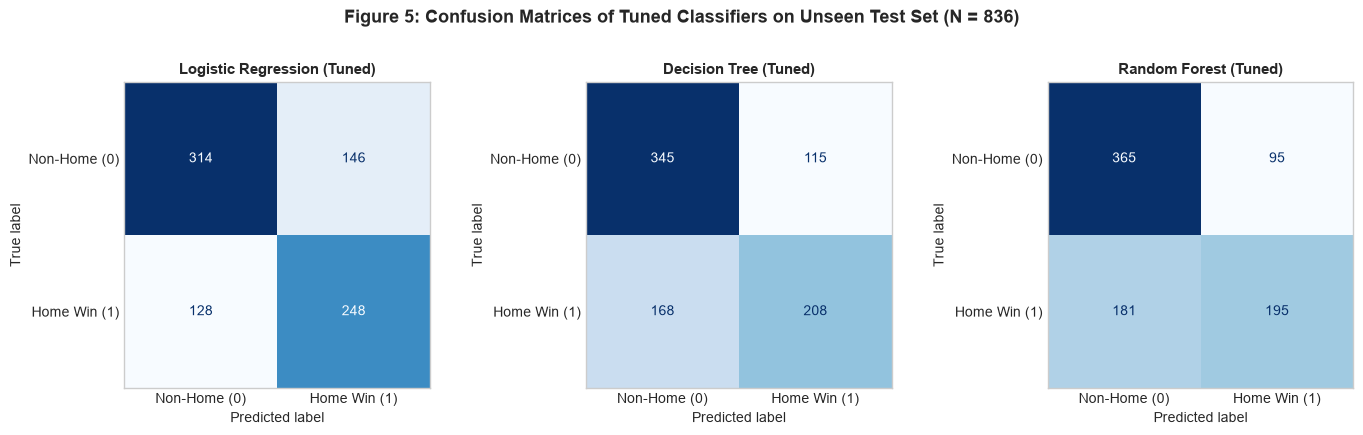

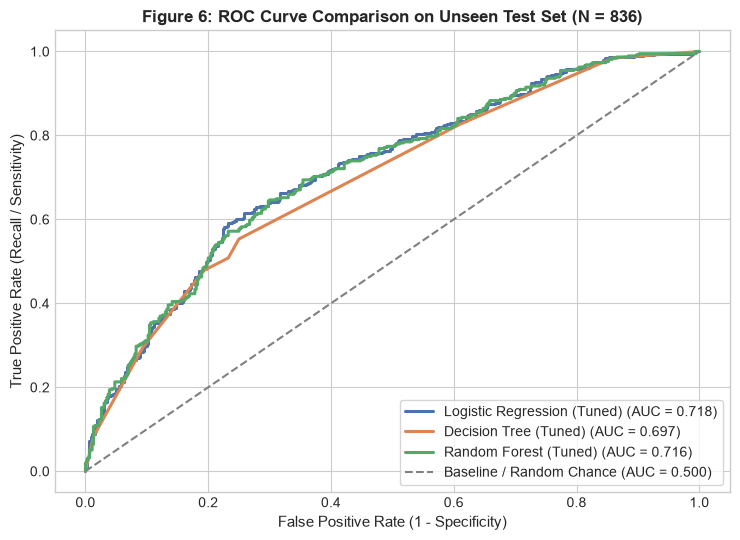

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('../report/figures', exist_ok=True)

# --- FIGURE 5: Side-by-side Confusion Matrices ---
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
tuned_names = [
    "Logistic Regression (Tuned)",
    "Decision Tree (Tuned)",
    "Random Forest (Tuned)"
]

for ax, name in zip(axes, tuned_names):
    cm = confusion_matrix(y_test, test_preds[name])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Home (0)', 'Home Win (1)'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(name, fontsize=11, weight='bold')
    ax.grid(False)

fig.suptitle('Figure 5: Confusion Matrices of Tuned Classifiers on Unseen Test Set (N = 836)', fontsize=13, weight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../report/figures/fig5_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

# --- FIGURE 6: Comparative ROC Curves ---
plt.figure(figsize=(7.5, 5.5))
colors = ['#4C72B0', '#DD8452', '#55A868']

for name, color in zip(tuned_names, colors):
    fpr, tpr, _ = roc_curve(y_test, test_probs[name])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2.2, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Baseline / Random Chance (AUC = 0.500)')
plt.title('Figure 6: ROC Curve Comparison on Unseen Test Set (N = 836)', fontsize=12, weight='bold')
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
plt.ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=11)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.savefig('../report/figures/fig6_roc_curves.png', dpi=300)
plt.show()

### 6. Model Interpretability: Standardised Coefficients & Feature Importance
To understand which pre-match signals drive match outcome predictions, we extract and visualise:
* **Standardised Coefficients** from the best-performing linear model (`Logistic Regression (Tuned)`), showing both direction and magnitude of each feature's effect on the log-odds of a home victory.
* **Gini Feature Importances** from `Random Forest (Tuned)`, measuring each predictor's relative contribution to impurity reduction across the ensemble.

--- EXACT CONFUSION MATRIX COUNTS ON TEST SET (N = 836) ---
Logistic Regression (Tuned)  -> TN: 314 | FP: 146 | FN: 128 | TP: 248
Decision Tree (Tuned)        -> TN: 345 | FP: 115 | FN: 168 | TP: 208
Random Forest (Tuned)        -> TN: 365 | FP:  95 | FN: 181 | TP: 195


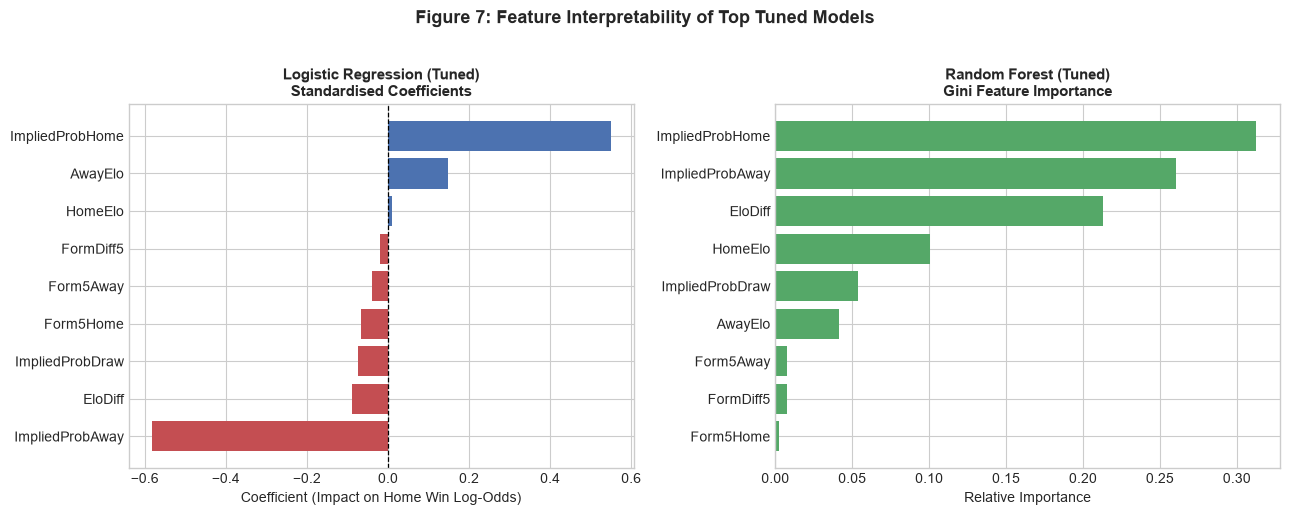

In [6]:
import seaborn as sns

# 1. Print exact confusion matrix counts (TN, FP, FN, TP) for accurate reporting
print("--- EXACT CONFUSION MATRIX COUNTS ON TEST SET (N = 836) ---")
for name in tuned_names:
    tn, fp, fn, tp = confusion_matrix(y_test, test_preds[name]).ravel()
    print(f"{name:28s} -> TN: {tn:3d} | FP: {fp:3d} | FN: {fn:3d} | TP: {tp:3d}")

# 2. Extract Logistic Regression coefficients and Random Forest importances
lr_clf = tuned_models["Logistic Regression (Tuned)"].named_steps['clf']
rf_clf = tuned_models["Random Forest (Tuned)"].named_steps['clf']

df_lr_coef = pd.DataFrame({
    'Feature': eng_features,
    'Coefficient': lr_clf.coef_[0]
}).sort_values(by='Coefficient', ascending=True)

df_rf_imp = pd.DataFrame({
    'Feature': eng_features,
    'Importance': rf_clf.feature_importances_
}).sort_values(by='Importance', ascending=True)

# 3. Plot Figure 7: Side-by-side Interpretability Chart
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: Logistic Regression Standardised Coefficients
colors_lr = ['#C44E52' if c < 0 else '#4C72B0' for c in df_lr_coef['Coefficient']]
axes[0].barh(df_lr_coef['Feature'], df_lr_coef['Coefficient'], color=colors_lr)
axes[0].axvline(0, color='black', linewidth=0.9, linestyle='--')
axes[0].set_title('Logistic Regression (Tuned)\nStandardised Coefficients', fontsize=11, weight='bold')
axes[0].set_xlabel('Coefficient (Impact on Home Win Log-Odds)', fontsize=10)

# Right: Random Forest Feature Importances
axes[1].barh(df_rf_imp['Feature'], df_rf_imp['Importance'], color='#55A868')
axes[1].set_title('Random Forest (Tuned)\nGini Feature Importance', fontsize=11, weight='bold')
axes[1].set_xlabel('Relative Importance', fontsize=10)

fig.suptitle('Figure 7: Feature Interpretability of Top Tuned Models', fontsize=13, weight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../report/figures/fig7_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()